# Demand modelling – part 1

Preparation of the SERL daily aggregated statistics, then the seasonal patterns of household groups (electricity and gas): winter/summer ratio, seasonal strength, change since 2020, and k-means clusters of seasonal shapes.

**Inputs:** `data/serl_daily_…_2020_to_2023_aggregated_statistics.csv` and `data/Clean_Aggregated_data_2020_2023.csv`.
**Outputs:** `outputs/forecasting_monthly.csv`, `outputs/subgroup_seasonality.csv`, `outputs/subgroup_clusters.csv`.


In [2]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# =============================================================================
# data prep pipeline (oop version) — patched
# =============================================================================

from __future__ import annotations

# stdlib
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional
import io  # needed to capture df.info() text

# third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Theme (no trailing commas!) ----------------
PRIMARY_COLOR    = "#12436D"  # Dark blue
TURQUOISE_COLOR  = "#28A197"  # Turquoise
DARK_PINK_COLOR  = "#801650"  # Dark pink
ORANGE_COLOR     = "#F46A25"  # Orange
DARK_GREY        = "#3D3D3D"  # Dark grey
LIGHT_PURPLE     = "#A285D1"  # Light purple
LIGHT_BG         = "#F5F5F5"  # Light gray background
DARK_TEXT        = "#333333"  # Dark text

PALETTE = [
    PRIMARY_COLOR, TURQUOISE_COLOR, DARK_PINK_COLOR, ORANGE_COLOR,
    DARK_GREY, LIGHT_PURPLE
]
YEAR_COLORS = {2020: PRIMARY_COLOR, 2021: TURQUOISE_COLOR, 2022: DARK_PINK_COLOR, 2023: ORANGE_COLOR}

def set_theme():
    plt.rcParams.update({
        "figure.figsize": (11, 6),
        "figure.dpi": 120,
        "figure.facecolor": "#ffffff",
        "axes.facecolor": "#ffffff",
        "axes.edgecolor": DARK_GREY,
        "axes.labelcolor": DARK_TEXT,
        "axes.titlesize": 16,
        "axes.titleweight": "bold",
        "grid.color": "#E6E6E6",
        "grid.alpha": 0.8,
        "axes.grid": True,
        "font.size": 12,
        "legend.frameon": False,
        "legend.edgecolor": "#00000000",
    })
    plt.rcParams['axes.prop_cycle'] = plt.cycler(color=PALETTE)
    # Times New Roman everywhere
    plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Times','serif']})

set_theme()

# =============================================================================
# configuration
# =============================================================================

@dataclass
class PrepConfig:
    """configuration for the data preparation pipeline.

    one-line summary:
        holds io paths, thresholds, and column rules for a reproducible run.

    args:
        csv_path: absolute or relative path to the input csv file.
        missing_drop_threshold: percentage (0–100) over which columns are dropped.
        rename_map: mapping from old column names to new names.
        drop_columns: explicit columns to drop after renaming (if present).
        random_seed: seed used to keep any stochastic steps reproducible.

    returns:
        none.
    """

    csv_path: Path
    missing_drop_threshold: float = 50.0
    rename_map: Dict[str, str] = field(
        default_factory=lambda: {
            # rename for clarity and consistency
            "segment_1_value": "primary_space_heating_fuel",
            "segment_2_value": "has_PV",
        }
    )
    drop_columns: List[str] = field(
        default_factory=lambda: ["segmentation_variable_1", "segmentation_variable_2", "summary_time"]
    )
    random_seed: int = 42


# =============================================================================
# pipeline
# =============================================================================

class DataPrepPipeline:
    """end-to-end data preparation and diagnostics for the energy dataset.

    one-line summary:
        loads, profiles, cleans, and returns a tidy dataframe with logs.

    args:
        config: instance of `PrepConfig` containing all run parameters.

    returns:
        none. use `.run()` to execute and retrieve the final dataframe.

    raises:
        filenotfounderror: if the csv path does not exist.
        valueerror: if input df is empty or badly formatted.
    """

    def __init__(self, config: PrepConfig):
        # keep run settings together for easy reproducibility
        self.cfg = config
        # seed numpy to keep any randomness deterministic
        np.random.seed(self.cfg.random_seed)

        # internal state holder
        self.df: Optional[pd.DataFrame] = None

    # -------------------------------------------------------------------------
    # io
    # -------------------------------------------------------------------------
    def load(self) -> pd.DataFrame:
        """load the csv with basic validation.

        returns:
            loaded dataframe.

        raises:
            filenotfounderror: if the file path is missing.
            valueerror: if the file loads but is empty.
        """
        path = Path(self.cfg.csv_path)
        if not path.exists():
            # fail early with a clear message
            raise FileNotFoundError(f"csv not found at: {path}")

        # read once; let pandas infer types reasonably
        df = pd.read_csv(path)

        if df.empty:
            # empty data is usually a bad sign worth stopping for
            raise ValueError("loaded dataframe is empty.")

        # store in state for subsequent steps
        self.df = df
        self._log(f"loaded shape: {df.shape[0]} rows × {df.shape[1]} cols")
        return df

    # -------------------------------------------------------------------------
    # quick diagnostics
    # -------------------------------------------------------------------------
    def basic_profile(self) -> dict:
        """produce a lightweight profile summary for sanity checks.

        returns:
            dictionary with head, info (as string), and describe summary.
        """
        self._ensure_loaded()

        # capture df.info() text into a string
        buf = io.StringIO()
        self.df.info(buf=buf)
        info_text = buf.getvalue()

        summary = {
            "shape": self.df.shape,
            "columns": list(self.df.columns),
            "dtypes": self.df.dtypes.astype(str).to_dict(),
            "info": info_text,
            "describe_numeric": self.df.describe().to_dict(),
            "head": self.df.head().to_dict(orient="records"),
        }

        self._log("generated basic profile.")
        return summary

    def inspect_categoricals(self) -> dict:
        """inspect object columns with counts and cardinalities.

        returns:
            mapping of column name to a small dict of stats.
        """
        self._ensure_loaded()

        cat_cols = self.df.select_dtypes(include="object").columns.tolist()
        out = {}
        for col in cat_cols:
            vc = self.df[col].value_counts(dropna=False)
            out[col] = {
                "nunique": int(self.df[col].nunique(dropna=False)),
                "top_values": vc.head(20).to_dict(),  # keep it compact
            }

        # special peek for 'quantity' if present
        if "quantity" in self.df.columns:
            out["_quantity_unique_preview"] = pd.unique(self.df["quantity"]).tolist()

        self._log(f"inspected {len(cat_cols)} categorical columns.")
        return out

    # -------------------------------------------------------------------------
    # missingness handling
    # -------------------------------------------------------------------------
    def missing_profile(self) -> pd.Series:
        """compute missing percentage per column.

        returns:
            series indexed by column with missing percentage (0–100).
        """
        self._ensure_loaded()

        missing_pct = self.df.isna().mean().mul(100).sort_values(ascending=False)
        self._log("computed missingness profile.")
        return missing_pct

    def drop_high_missing(self, missing_pct: Optional[pd.Series] = None) -> List[str]:
        """drop columns over the configured missingness threshold.

        args:
            missing_pct: optional precomputed missing series to reuse.

        returns:
            list of columns dropped.
        """
        self._ensure_loaded()

        if missing_pct is None:
            missing_pct = self.missing_profile()

        threshold = self.cfg.missing_drop_threshold
        to_drop = missing_pct[missing_pct > threshold].index.tolist()

        # drop in place if any
        if to_drop:
            self.df.drop(columns=to_drop, inplace=True, errors="ignore")
            self._log(f"dropped {len(to_drop)} high-missing columns (> {threshold}%): {to_drop}")
        else:
            self._log("no columns exceeded missingness threshold.")

        return to_drop

    # -------------------------------------------------------------------------
    # schema cleanup
    # -------------------------------------------------------------------------
    def rename_columns(self) -> Dict[str, str]:
        """rename columns using the configured mapping.

        returns:
            the mapping actually applied (only existing keys).
        """
        self._ensure_loaded()

        existing_map = {k: v for k, v in self.cfg.rename_map.items() if k in self.df.columns}
        if existing_map:
            self.df.rename(columns=existing_map, inplace=True)
            self._log(f"renamed columns: {existing_map}")
        else:
            self._log("no columns matched for renaming.")

        return existing_map

    def drop_columns(self) -> List[str]:
        """drop configured columns if they are present.

        returns:
            list of columns actually dropped.
        """
        self._ensure_loaded()

        present = [c for c in self.cfg.drop_columns if c in self.df.columns]
        if present:
            self.df.drop(columns=present, inplace=True, errors="ignore")
            self._log(f"dropped redundant columns: {present}")
        else:
            self._log("no redundant columns found to drop.")

        return present

    # -------------------------------------------------------------------------
    # orchestrator
    # -------------------------------------------------------------------------
    def run(self) -> pd.DataFrame:
        """run the full pipeline in the intended order.

        returns:
            cleaned dataframe ready for downstream work.
        """
        self.load()

        # quick, non-fatal diagnostics (kept for exploration)
        _ = self.basic_profile()
        _ = self.inspect_categoricals()

        # missingness → drop too-empty columns, then tidy names, then drop noise
        miss = self.missing_profile()
        _ = self.drop_high_missing(miss)
        _ = self.rename_columns()
        _ = self.drop_columns()

        self._log(f"final shape: {self.df.shape[0]} rows × {self.df.shape[1]} cols")
        return self.df.copy(deep=True)

    # -------------------------------------------------------------------------
    # internals
    # -------------------------------------------------------------------------
    def _ensure_loaded(self) -> None:
        """ensure dataframe is loaded before any operation.

        raises:
            runtimeerror: if `self.df` is None.
        """
        if self.df is None:
            # nudge the caller to run load()/run() first
            raise RuntimeError("dataframe is not loaded; call .load() or .run() first.")

    @staticmethod
    def _log(msg: str) -> None:
        """lightweight logger for consistent, quiet console messages.

        args:
            msg: message to print.

        returns:
            none.
        """
        print(f"[prep] {msg}")


# =============================================================================
# usage example (script entrypoint)
# =============================================================================

def main() -> None:
    """script entrypoint to run the pipeline end-to-end.

    returns:
        none.
    """
    # # todo: issue #1 add cli args via argparse if needed.

    # set up config; path can be relative to cwd
    cfg = PrepConfig(
        csv_path=Path("data/serl_daily_energy_use_in_gb_domestic_buildings_2020_to_2023_aggregated_statistics.csv"),
        missing_drop_threshold=50.0,
    )

    # run the pipeline
    pipe = DataPrepPipeline(cfg)
    cleaned = pipe.run()

    # small peek to confirm things look ok
    print("\n== preview of cleaned data ==")
    print(cleaned.head(10))


if __name__ == "__main__":
    # keep top-level side effects minimal and predictable
    main()


[prep] loaded shape: 531180 rows × 21 cols
[prep] generated basic profile.
[prep] inspected 11 categorical columns.
[prep] computed missingness profile.
[prep] no columns exceeded missingness threshold.
[prep] renamed columns: {'segment_1_value': 'primary_space_heating_fuel', 'segment_2_value': 'has_PV'}
[prep] dropped redundant columns: ['segmentation_variable_1', 'segmentation_variable_2', 'summary_time']
[prep] final shape: 531180 rows × 18 cols

== preview of cleaned data ==
              quantity            unit aggregation_period weekday_weekend  \
0                  Gas         kWh/day               2020            both   
1                  Gas         kWh/day               2020            both   
2                  Gas         kWh/day               2020            both   
3                  Gas      kWh/m2/day               2020            both   
4                  Gas      kWh/m2/day               2020            both   
5                  Gas      kWh/m2/day               2

In [3]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# =============================================================================
# data prep pipeline (oop version) — extended with dedupe, iqr outliers, cleaning, and ts snapshot
# =============================================================================

from __future__ import annotations

# stdlib
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import io

# third-party
import numpy as np
import pandas as pd


# =============================================================================
# configuration
# =============================================================================

@dataclass
class PrepConfig:
    """configuration for the data preparation pipeline.

    one-line summary:
        holds io paths, thresholds, and column rules for a reproducible run.

    args:
        csv_path: path to input csv.
        missing_drop_threshold: percentage (0–100) over which columns are dropped.
        rename_map: mapping from old column names to new names.
        drop_columns: explicit columns to drop after renaming (if present).
        random_seed: seed to keep runs reproducible.
        save_forecasting_csv: whether to write the final timeseries snapshot.
        forecasting_csv_path: output path for the snapshot csv.
        outlier_iqr_multiplier: iqr fence multiplier used for outlier counting.
    returns:
        none.
    """

    csv_path: Path
    missing_drop_threshold: float = 50.0
    rename_map: Dict[str, str] = field(
        default_factory=lambda: {
            # rename for clarity and consistency
            "segment_1_value": "primary_space_heating_fuel",
            "segment_2_value": "has_PV",
        }
    )
    drop_columns: List[str] = field(
        default_factory=lambda: ["segmentation_variable_1", "segmentation_variable_2", "summary_time"]
    )
    random_seed: int = 42
    save_forecasting_csv: bool = True
    forecasting_csv_path: Path = Path("outputs/forecasting_monthly.csv")  # fixme: path can be overridden via cli later
    outlier_iqr_multiplier: float = 1.5


# =============================================================================
# pipeline
# =============================================================================

class DataPrepPipeline:
    """end-to-end data preparation and diagnostics for the energy dataset.

    one-line summary:
        loads, profiles, cleans, dedupes, reports outliers, and emits a tidy timeseries.

    args:
        config: instance of `PrepConfig` containing all run parameters.

    returns:
        none. use `.run()` to execute and retrieve the final dataframe.

    raises:
        filenotfounderror: if the csv path does not exist.
        valueerror: if input df is empty or badly formatted.
    """

    def __init__(self, config: PrepConfig):
        # keep run settings together for easy reproducibility
        self.cfg = config
        # seed numpy to keep any randomness deterministic
        np.random.seed(self.cfg.random_seed)

        # internal state holder
        self.df: Optional[pd.DataFrame] = None

    # -------------------------------------------------------------------------
    # io
    # -------------------------------------------------------------------------
    def load(self) -> pd.DataFrame:
        """load the csv with basic validation.

        returns:
            loaded dataframe.

        raises:
            filenotfounderror: if the file path is missing.
            valueerror: if the file loads but is empty.
        """
        path = Path(self.cfg.csv_path)
        if not path.exists():
            # fail early with a clear message
            raise FileNotFoundError(f"csv not found at: {path}")

        df = pd.read_csv(path)

        if df.empty:
            raise ValueError("loaded dataframe is empty.")

        self.df = df
        self._log(f"loaded shape: {df.shape[0]} rows × {df.shape[1]} cols")
        return df

    # -------------------------------------------------------------------------
    # quick diagnostics
    # -------------------------------------------------------------------------
    def basic_profile(self) -> dict:
        """produce a lightweight profile summary for sanity checks.

        returns:
            dictionary with head, info (as string), and describe summary.
        """
        self._ensure_loaded()

        buf = io.StringIO()
        self.df.info(buf=buf)
        info_text = buf.getvalue()

        summary = {
            "shape": self.df.shape,
            "columns": list(self.df.columns),
            "dtypes": self.df.dtypes.astype(str).to_dict(),
            "info": info_text,
            "describe_numeric": self.df.describe().to_dict(),
            "head": self.df.head().to_dict(orient="records"),
        }

        self._log("generated basic profile.")
        return summary

    def inspect_categoricals(self) -> dict:
        """inspect object columns with counts and cardinalities.

        returns:
            mapping of column name to a small dict of stats.
        """
        self._ensure_loaded()

        cat_cols = self.df.select_dtypes(include="object").columns.tolist()
        out = {}
        for col in cat_cols:
            vc = self.df[col].value_counts(dropna=False)
            out[col] = {
                "nunique": int(self.df[col].nunique(dropna=False)),
                "top_values": vc.head(20).to_dict(),
            }

        if "quantity" in self.df.columns:
            out["_quantity_unique_preview"] = pd.unique(self.df["quantity"]).tolist()

        self._log(f"inspected {len(cat_cols)} categorical columns.")
        return out

    # -------------------------------------------------------------------------
    # missingness handling
    # -------------------------------------------------------------------------
    def missing_profile(self) -> pd.Series:
        """compute missing percentage per column.

        returns:
            series indexed by column with missing percentage (0–100).
        """
        self._ensure_loaded()
        missing_pct = self.df.isna().mean().mul(100).sort_values(ascending=False)
        self._log("computed missingness profile.")
        return missing_pct

    def drop_high_missing(self, missing_pct: Optional[pd.Series] = None) -> List[str]:
        """drop columns over the configured missingness threshold.

        args:
            missing_pct: optional precomputed missing series to reuse.

        returns:
            list of columns dropped.
        """
        self._ensure_loaded()

        if missing_pct is None:
            missing_pct = self.missing_profile()

        threshold = self.cfg.missing_drop_threshold
        to_drop = missing_pct[missing_pct > threshold].index.tolist()

        if to_drop:
            self.df.drop(columns=to_drop, inplace=True, errors="ignore")
            self._log(f"dropped {len(to_drop)} high-missing columns (> {threshold}%): {to_drop}")
        else:
            self._log("no columns exceeded missingness threshold.")

        return to_drop

    # -------------------------------------------------------------------------
    # schema cleanup
    # -------------------------------------------------------------------------
    def rename_columns(self) -> Dict[str, str]:
        """rename columns using the configured mapping.

        returns:
            the mapping actually applied (only existing keys).
        """
        self._ensure_loaded()

        existing_map = {k: v for k, v in self.cfg.rename_map.items() if k in self.df.columns}
        if existing_map:
            self.df.rename(columns=existing_map, inplace=True)
            self._log(f"renamed columns: {existing_map}")
        else:
            self._log("no columns matched for renaming.")
        return existing_map

    def drop_columns(self) -> List[str]:
        """drop configured columns if they are present.

        returns:
            list of columns actually dropped.
        """
        self._ensure_loaded()

        present = [c for c in self.cfg.drop_columns if c in self.df.columns]
        if present:
            self.df.drop(columns=present, inplace=True, errors="ignore")
            self._log(f"dropped redundant columns: {present}")
        else:
            self._log("no redundant columns found to drop.")
        return present

    # -------------------------------------------------------------------------
    # dedupe + outliers (iqr)
    # -------------------------------------------------------------------------
    def duplicate_report(self) -> int:
        """count duplicate rows without altering the dataframe.

        returns:
            number of duplicated rows.
        """
        self._ensure_loaded()
        n_dup = int(self.df.duplicated().sum())
        self._log(f"duplicate rows found: {n_dup}")
        return n_dup

    def outlier_report_iqr(self, multiplier: Optional[float] = None) -> Dict[str, int]:
        """count potential outliers per numeric column using iqr fences.

        args:
            multiplier: iqr multiplier; defaults to config value.

        returns:
            mapping from numeric column name to outlier count.
        """
        self._ensure_loaded()

        k = multiplier if multiplier is not None else self.cfg.outlier_iqr_multiplier
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns
        counts: Dict[str, int] = {}

        for col in numeric_cols:
            series = self.df[col].dropna()
            if series.empty:
                counts[col] = 0
                continue
            q1 = series.quantile(0.25)
            q3 = series.quantile(0.75)
            iqr = q3 - q1
            # avoid zero-width iqr exploding counts
            if iqr == 0:
                counts[col] = 0
                continue
            lower = q1 - k * iqr
            upper = q3 + k * iqr
            counts[col] = int(((self.df[col] < lower) | (self.df[col] > upper)).sum())

        self._log("computed iqr outlier counts for numeric columns.")
        return counts

    # -------------------------------------------------------------------------
    # cleaning + encoding + timeseries snapshot
    # -------------------------------------------------------------------------
    def clean_and_encode_df(self) -> pd.DataFrame:
        """clean and encode dataframe consistently with downstream ts analysis.

        returns:
            cleaned dataframe (still in internal state).
        """
        self._ensure_loaded()
        df = self.df

        # convert selected categoricals if present
        categorical_cols = [
            "quantity",
            "unit",
            "weekday_weekend",
            "primary_space_heating_fuel",
            "has_PV",
            "segmentation_variable_3",
            "segment_3_value",
        ]
        existing_cats = [c for c in categorical_cols if c in df.columns]
        if existing_cats:
            df[existing_cats] = df[existing_cats].astype("category")

        # ensure aggregation_period is a column, not index
        if "aggregation_period" not in df.columns and df.index.name == "aggregation_period":
            df.reset_index(inplace=True)

        # parse yyyy-mm strings → datetime64[m]
        if "aggregation_period" in df.columns:
            df["aggregation_period"] = df["aggregation_period"].astype(str)
            df = df[df["aggregation_period"].str.len() == 7]  # keep only yyyy-mm
            df["aggregation_period"] = pd.to_datetime(df["aggregation_period"], format="%Y-%m", errors="coerce")

        # drop rows missing 'mean' or invalid aggregation_period if both exist
        if {"mean", "aggregation_period"}.issubset(df.columns):
            df = df[df["mean"].notna() & df["aggregation_period"].notna()]

        # numeric coercion for expected metrics (silently coerce bad strings → NaN)
        numeric_cols = [
            "mean",
            "standard_deviation",
            "standard_error_mean",
            "75th_percentile",
            "mean_temp",
            "mean_solar",
            "median",
            "25th_percentile",
        ]
        existing_nums = [c for c in numeric_cols if c in df.columns]
        if existing_nums:
            df[existing_nums] = df[existing_nums].apply(pd.to_numeric, errors="coerce")

        # downcast counts to integer where possible
        if "n_rounded" in df.columns:
            df["n_rounded"] = pd.to_numeric(df["n_rounded"], errors="coerce", downcast="integer")

        # persist cleaned frame back to state
        self.df = df
        self._log("completed cleaning + encoding.")
        return self.df

    def finalize_timeseries(self) -> pd.DataFrame:
        """sort by aggregation_period, set it as index, and optionally save csv.

        returns:
            finalized timeseries dataframe (indexed by aggregation_period).
        """
        self._ensure_loaded()

        if "aggregation_period" not in self.df.columns:
            # nothing to do; keep as-is but warn
            self._log("aggregation_period not found; skipping timeseries indexing.")
            return self.df

        # sort then index for time-series analysis
        self.df = self.df.sort_values(by="aggregation_period").set_index("aggregation_period")

        # write snapshot if requested (file name standardized to 'forecasting.csv')
        if self.cfg.save_forecasting_csv:
            out_path = Path(self.cfg.forecasting_csv_path)
            # todo: make parent dirs if needed
            self.df.to_csv(out_path, index=True)
            self._log(f"wrote timeseries snapshot to: {out_path}")

        return self.df

    # -------------------------------------------------------------------------
    # orchestrator
    # -------------------------------------------------------------------------
    def run(self) -> pd.DataFrame:
        """run the full pipeline in the intended order.

        returns:
            cleaned dataframe ready for downstream work (indexed by aggregation_period if present).
        """
        self.load()

        # quick, non-fatal diagnostics
        _ = self.basic_profile()
        _ = self.inspect_categoricals()

        # missingness → drop too-empty columns, then tidy names, then drop noise
        miss = self.missing_profile()
        _ = self.drop_high_missing(miss)
        _ = self.rename_columns()
        _ = self.drop_columns()

        # dedupe report and iqr report (no mutation; just info)
        _ = self.duplicate_report()
        _ = self.outlier_report_iqr()

        # canonical cleaning + encoding
        _ = self.clean_and_encode_df()

        # finalize timeseries and optionally save csv
        final_df = self.finalize_timeseries()

        self._log(f"final shape: {final_df.shape[0]} rows × {final_df.shape[1]} cols")
        return final_df.copy(deep=True)

    # -------------------------------------------------------------------------
    # internals
    # -------------------------------------------------------------------------
    def _ensure_loaded(self) -> None:
        """ensure dataframe is loaded before any operation.

        raises:
            runtimeerror: if `self.df` is None.
        """
        if self.df is None:
            raise RuntimeError("dataframe is not loaded; call .load() or .run() first.")

    @staticmethod
    def _log(msg: str) -> None:
        """lightweight logger for consistent, quiet console messages.

        args:
            msg: message to print.

        returns:
            none.
        """
        print(f"[prep] {msg}")


# =============================================================================
# usage example (script entrypoint)
# =============================================================================

def main() -> None:
    """script entrypoint to run the pipeline end-to-end.

    returns:
        none.
    """
    # todo: add argparse for --csv-path, --missing-threshold, --out path.

    cfg = PrepConfig(
        csv_path=Path("data/serl_daily_energy_use_in_gb_domestic_buildings_2020_to_2023_aggregated_statistics.csv"),
        missing_drop_threshold=50.0,
        forecasting_csv_path=Path("outputs/forecasting_monthly.csv"),  # note: standardized spelling
        save_forecasting_csv=True,
        outlier_iqr_multiplier=1.5,
    )

    pipe = DataPrepPipeline(cfg)
    final_df = pipe.run()

    print("\n== preview of finalized timeseries ==")
    print(final_df.head(10))


if __name__ == "__main__":
    # keep top-level side effects minimal and predictable
    main()


[prep] loaded shape: 531180 rows × 21 cols
[prep] generated basic profile.
[prep] inspected 11 categorical columns.
[prep] computed missingness profile.
[prep] no columns exceeded missingness threshold.
[prep] renamed columns: {'segment_1_value': 'primary_space_heating_fuel', 'segment_2_value': 'has_PV'}
[prep] dropped redundant columns: ['segmentation_variable_1', 'segmentation_variable_2', 'summary_time']
[prep] duplicate rows found: 0
[prep] computed iqr outlier counts for numeric columns.


/var/folders/h3/_fbfc5sj6c72snx97hvxhzq00000gn/T/ipykernel_3029/1983169035.py:326: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["aggregation_period"] = pd.to_datetime(df["aggregation_period"], format="%Y-%m", errors="coerce")


[prep] completed cleaning + encoding.
[prep] wrote timeseries snapshot to: forecasting.csv
[prep] final shape: 380126 rows × 17 cols

== preview of finalized timeseries ==
                           quantity            unit weekday_weekend  \
aggregation_period                                                    
2020-01-01                      Gas         kWh/day            both   
2020-01-01          Electricity net  kWh/person/day         weekend   
2020-01-01          Electricity net  kWh/person/day         weekend   
2020-01-01          Electricity net  kWh/person/day         weekend   
2020-01-01          Electricity net  kWh/person/day         weekend   
2020-01-01          Electricity net  kWh/person/day         weekend   
2020-01-01          Electricity net         kWh/day            both   
2020-01-01          Electricity net         kWh/day            both   
2020-01-01          Electricity net         kWh/day            both   
2020-01-01          Electricity net  kWh/person

## Seasonal patterns of household groups

How strongly does each group of households' electricity and gas use rise in winter, and which groups behave alike?

Each group's series is taken with `serl_utils`: one quantity, one unit (kWh/day), all days, all other households in the group. The earlier version of this notebook built one "series" per quantity × unit × PV status by stacking every region, EPC band, tenure, … for the same month (227 rows per month). SARIMA forecasts of those stacked rows were then clustered, which produced negative forecasts and labelled 44 of 45 subgroups "Winter Peaker". That analysis and the scenario multipliers that followed are replaced here; evidence-based load shifting is now in `TariffSimulation.ipynb`.

**Measures per group:** mean 2023 use, winter/summer ratio (Dec–Feb vs Jun–Aug), STL seasonal strength (0 = none, 1 = purely seasonal) and the change in mean use from 2020 to 2023.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serl_utils as su

warnings.filterwarnings("ignore", category=UserWarning)
monthly_all = su.load_monthly(su.CLEAN_CSV)
# keep only rows these analyses use (per-household kWh/day, all days) to make slicing fast
monthly = monthly_all[monthly_all["unit"].eq("kWh/day") & monthly_all["weekday_weekend"].eq("both")]

# household groups: whole sample, PV, heating fuel, and every SERL segment level except temperature band
# (temperature band describes the weather on a day, not a type of household)
SEGMENTS = [s for s in monthly["segmentation_variable_3"].dropna().unique() if s != "temperature_band"]
GROUPS = [("All households", {})]
GROUPS += [(f"PV: {v}", {"pv": v}) for v in ("Yes", "No")]
GROUPS += [(f"Heating fuel: {v}", {"fuel": v}) for v in ("Gas", "Electric")]
for seg in SEGMENTS:
    levels = sorted(monthly.loc[monthly["segmentation_variable_3"].eq(seg), "segment_3_value"].dropna().astype(str).unique())
    levels = [lv for lv in levels if lv != "All"]   # "All" repeats the whole sample
    GROUPS += [(f"{seg}: {lv}", {"segment": seg, "segment_value": lv}) for lv in levels]
print(f"{len(GROUPS)} household groups from {len(SEGMENTS)} SERL segment variables + PV + heating fuel")
from statsmodels.tsa.seasonal import STL

QUANTITIES = ["Electricity imports", "Gas"]
WINTER, SUMMER = [12, 1, 2], [6, 7, 8]

def seasonal_strength(y):
    res = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))

series, rows, skipped = {q: {} for q in QUANTITIES}, [], []
for q in QUANTITIES:
    for name, f in GROUPS:
        s = su.monthly_series(monthly, q, "kWh/day", **f)
        if s.isna().any():                      # SERL suppresses months with too few households
            skipped.append(f"{q} | {name} ({s.isna().sum()} months missing)")
            continue
        series[q][name] = s
        rows.append({"quantity": q, "group": name, "kWh/day 2023": s.loc["2023"].mean(),
                     "winter/summer ratio": s[s.index.month.isin(WINTER)].mean() / s[s.index.month.isin(SUMMER)].mean(),
                     "seasonal strength": seasonal_strength(s),
                     "change 2020→2023 %": 100 * (s.loc["2023"].mean() / s.loc["2020"].mean() - 1)})
seasonality = pd.DataFrame(rows)
print(f"Skipped (incomplete series): {len(skipped)}")
for line in skipped:
    print("  ", line)

for q in QUANTITIES:
    t = seasonality[seasonality["quantity"].eq(q)].set_index("group").drop(columns="quantity")
    print(f"\n{q}: {len(t)} groups. Most and least seasonal (winter/summer ratio)")
    print(pd.concat([t.nlargest(6, "winter/summer ratio"), t.nsmallest(6, "winter/summer ratio")]).round(2).to_string())
seasonality.to_csv("outputs/subgroup_seasonality.csv", index=False)
print("\nSaved outputs/subgroup_seasonality.csv")

75 household groups from 11 SERL segment variables + PV + heating fuel


Skipped (incomplete series): 6
   Gas | central_heating_type: District or community (48 months missing)
   Gas | central_heating_type: Electric radiators (1 months missing)
   Gas | central_heating_type: Electric storage radiators (6 months missing)
   Gas | central_heating_type: Oil, solid fuel or biomass (48 months missing)
   Gas | central_heating_type: Other electric (48 months missing)
   Gas | central_heating_type: Other or other mix (1 months missing)

Electricity imports: 75 groups. Most and least seasonal (winter/summer ratio)
                                                  kWh/day 2023  winter/summer ratio  seasonal strength  change 2020→2023 %
group                                                                                                                     
central_heating_type: Electric storage radiators         13.61                 3.49               0.95              -18.93
central_heating_type: Other electric                     18.39                 3.17      

### Clustering the seasonal shapes

Each group's 2020–2023 series is averaged by calendar month and divided by its own mean, so groups are compared on the *shape* of their year, not their size. k-means is run for k = 2–6 and k is chosen by silhouette score (the largest k within 0.01 of the best score). Clusters are named by their winter/summer ratio.


Electricity imports: silhouette by k {2: 0.835, 3: 0.448, 4: 0.428, 5: 0.402, 6: 0.397} -> k = 2
  largest monthly difference between cluster shapes: 0.39 x the group mean
  More seasonal (winter/summer ratio 2.78, 6 groups):
    PV: Yes; Heating fuel: Electric; central_heating_type: Electric radiators; central_heating_type: Electric storage radiators; central_heating_type: Other electric; central_heating_type: Other or other mix
  Less seasonal (winter/summer ratio 1.51, 69 groups):
    All households; PV: No; Heating fuel: Gas; num_bedrooms: 1; num_bedrooms: 2; num_bedrooms: 3; num_bedrooms: 4; num_bedrooms: >=5; num_bedrooms: No data; num_occupants: 1; num_occupants: 2; num_occupants: 3; num_occupants: 4; num_occupants: 5; num_occupants: >=6; num_occupants: No data; building_type: Commercial building or no answer; building_type: Converted flat or shared house; building_type: Detached; building_type: Purpose-built flat; building_type: Semi-detached; building_type: Terraced; IMD_quint

  Less seasonal (winter/summer ratio 6.35, 23 groups):
    Heating fuel: Electric; num_bedrooms: 1; num_bedrooms: No data; num_occupants: 5; num_occupants: >=6; num_occupants: No data; building_type: Commercial building or no answer; building_type: Converted flat or shared house; building_type: Purpose-built flat; building_age: 1991 - 2002; building_age: 2003 onwards; building_age: No data; region: North East; region: Scotland; floor_area_m2: 50 or less; floor_area_m2: Over 200; tenure: No answer; tenure: Part-own part-rent; tenure: Private rent; tenure: Rent free; tenure: Social rent; has_ev: No data; currentEnergyRating: A and B



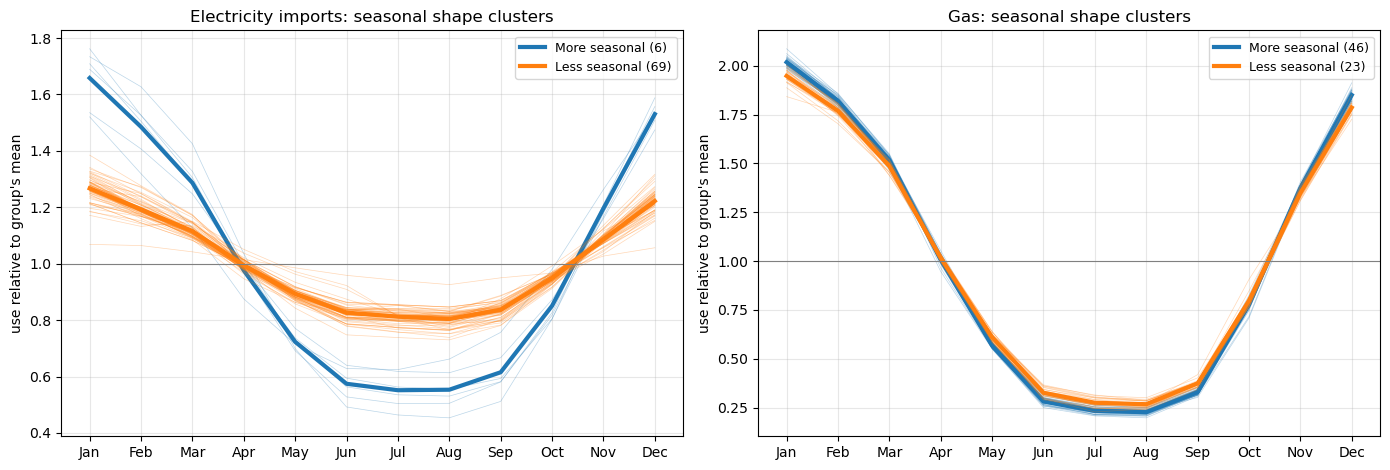

                                   kWh/day 2023  winter/summer ratio  change 2020→2023 %
quantity            cluster                                                             
Electricity imports Less seasonal          8.84                 1.51              -18.28
                    More seasonal         13.09                 2.83              -20.16
Gas                 Less seasonal         27.54                 6.38              -18.70
                    More seasonal         30.31                 7.70              -20.14

Saved outputs/subgroup_clusters.csv


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def choose_k(X, ks=range(2, 7)):
    scores = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=42).fit_predict(X)) for k in ks}
    best = max(scores.values())
    return max(k for k, s in scores.items() if s >= best - 0.01), scores

assignments = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, q in zip(axes, QUANTITIES):
    shapes = pd.DataFrame({g: s.groupby(s.index.month).mean() / s.mean() for g, s in series[q].items()}).T
    k, scores = choose_k(shapes)
    labels = KMeans(k, n_init=20, random_state=42).fit_predict(shapes)
    centroids = shapes.groupby(labels).mean()
    ratio = centroids[WINTER].mean(axis=1) / centroids[SUMMER].mean(axis=1)
    names = ["Strongly seasonal", "Moderately seasonal", "Weakly seasonal"] if k == 3 else \
            ["More seasonal", "Less seasonal"] if k == 2 else [f"Seasonality rank {i + 1}" for i in range(k)]
    name_of = {c: names[r] for r, c in enumerate(ratio.sort_values(ascending=False).index)}
    print(f"{q}: silhouette by k {({kk: round(v, 3) for kk, v in scores.items()})} -> k = {k}")
    gap = (centroids.max() - centroids.min()).max()
    print(f"  largest monthly difference between cluster shapes: {gap:.2f} x the group mean")
    for c in ratio.sort_values(ascending=False).index:
        members = shapes.index[labels == c].tolist()
        print(f"  {name_of[c]} (winter/summer ratio {ratio[c]:.2f}, {len(members)} groups):")
        print("    " + "; ".join(members))
        ax.plot(range(12), centroids.loc[c], linewidth=3, label=f"{name_of[c]} ({len(members)})")
        for g in members:
            ax.plot(range(12), shapes.loc[g], linewidth=0.5, alpha=0.3, color=ax.lines[-1].get_color())
    for g, lab in zip(shapes.index, labels):
        assignments.append({"quantity": q, "group": g, "cluster": name_of[lab]})
    ax.set_xticks(range(12), MONTHS); ax.axhline(1, color="grey", linewidth=0.8)
    ax.set_ylabel("use relative to group's mean"); ax.set_title(f"{q}: seasonal shape clusters")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    print()
plt.tight_layout(); plt.show()

clusters = pd.DataFrame(assignments).merge(seasonality, on=["quantity", "group"])
print(clusters.groupby(["quantity", "cluster"])[["kWh/day 2023", "winter/summer ratio", "change 2020→2023 %"]]
      .mean().round(2).to_string())
clusters.to_csv("outputs/subgroup_clusters.csv", index=False)
print("\nSaved outputs/subgroup_clusters.csv")

**Reading the results**
- **Electricity:** homes with electric heating, and PV homes, form a separate, much more seasonal cluster (winter use about 2.8 times summer use, against about 1.5 times for all other groups). For PV homes this mainly reflects lower *summer imports* because solar covers part of the demand, not higher winter demand.
- **Gas:** every group follows almost the same seasonal shape (see the largest difference printed above), so gas seasonality is close to universal. The split only separates groups with a slightly stronger winter peak (least efficient homes, EPC E–G, pre-1930 buildings, single occupants) from the rest.
- **Change since 2020:** every group used less electricity and gas in 2023 than in 2020 (see `change 2020→2023 %` in the tables).
